In [10]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
import h5py
import matplotlib.pyplot as plt
import pandas as pd
from dingo.gw.noise.asd_dataset import ASDDataset
import yaml
import pycbc.psd
import numpy as np

In [11]:
font_value = 20

# Set global Matplotlib settings for a clean look without grids
plt.rcParams['axes.grid'] = False      # Disable grid lines for all axes
plt.rcParams['grid.color'] = 'none'    # Just in case, ensure grid color is invisible
# Set matplotlib to render LaTeX fonts
plt.rcParams.update({
    "mathtext.fontset" : "stix",
    "font.family" : "STIXGeneral",
    "axes.labelsize": font_value ,           # Font size for axis labels
    "axes.titlesize": font_value ,           # Font size for titles
    "font.size": font_value ,                # General font size
    "legend.fontsize": font_value ,          # Font size for legend
    "xtick.labelsize": font_value ,          # Font size for x-axis ticks
    "ytick.labelsize": font_value ,          # Font size for y-axis ticks
})

from matplotlib_inline.backend_inline import set_matplotlib_formats
# Enable retina display output in Jupyter
set_matplotlib_formats("retina")

In [12]:
#ASD dataset settings:
f_min= 6        
f_max= 256    
f_s = f_max*2.0 
T= 8.0
delta_f = 1.0 / T
time_psd= 1024

Name = 'ET_10km_2026a_HF'

In [13]:
#create PSD File for Bilby
#with open('18213_ET10kmcolumns.txt', 'r') as f_in, open('ET_PSD_10km.txt', 'w') as f_out:
#    for line in f_in:
#        cols = line.split()
#        if len(cols) >= 4:
#            f_out.write(f"{cols[0]} {cols[-1]}\n")
#

In [14]:
import numpy as np

# Datei einladen (NumPy erkennt Leerzeichen automatisch)
data = np.loadtxt('et_10_psd_HF.txt')

# Quadratwurzel nur für die zweite Spalte berechnen (Index 1)
data[:, 1] = np.sqrt(data[:, 1])

# Speichern (mit wissenschaftlicher Notation wie im Original)
np.savetxt('et_10_asd_HF.txt', data, fmt='%.18e')


In [15]:
# Load ET ASD data from text file
ET_ASD = pd.read_csv(
    "et_10_psd_HF.txt",
    delimiter = ' ',
    header=None,
    usecols=[0, 1],         # first and last column
    names=["frequency", "PSD"]
)
# Calculate ASD from PSD
ET_ASD['ASD'] = np.sqrt(ET_ASD['PSD'])
ET_ASD = ET_ASD[ET_ASD["frequency"] <= f_max].reset_index(drop=True)

ET_ASD

,frequency,PSD,ASD
0,1.000000,1.986095e-33,4.456562e-17
1,1.003076,2.203323e-33,4.693957e-17
2,1.006161,2.454674e-33,4.954467e-17
3,1.009256,2.745711e-33,5.239953e-17
4,1.012360,3.101853e-33,5.569428e-17
...,...,...,...
1801,252.425976,1.169160e-49,3.419298e-25
1802,253.202403,1.168688e-49,3.418608e-25
1803,253.981217,1.168224e-49,3.417929e-25
1804,254.762428,1.167767e-49,3.417261e-25


In [16]:
#resample asd to lenght fmax / delta_f + 1
f_new = np.arange(0, f_max + delta_f, delta_f)

PSD_new = np.interp(f_new, ET_ASD["frequency"], ET_ASD["ASD"])
ASD_new = np.interp(f_new, ET_ASD["frequency"], ET_ASD["ASD"])

ET_ASD_resampled = pd.DataFrame({
    "f": f_new,
    "h(f)": ASD_new
})

ET_ASD_resampled

,f,h(f)
0,0.000,4.456562e-17
1,0.125,4.456562e-17
2,0.250,4.456562e-17
3,0.375,4.456562e-17
4,0.500,4.456562e-17
...,...,...
2044,255.500,3.416643e-25
2045,255.625,3.416605e-25
2046,255.750,3.416605e-25
2047,255.875,3.416605e-25


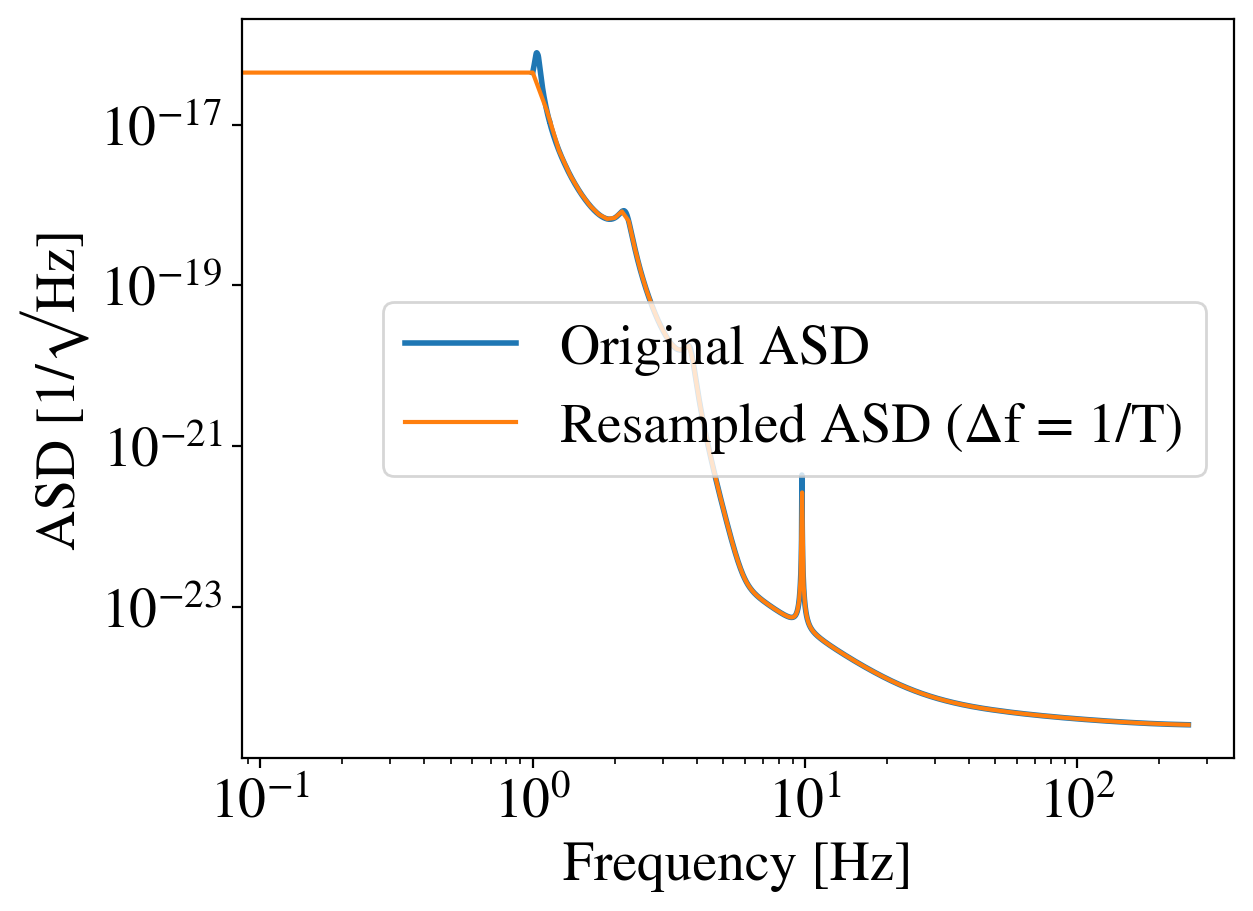

In [17]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(
    ET_ASD["frequency"],
    ET_ASD["ASD"],
    label="Original ASD",
    linewidth=2
)

plt.plot(
    ET_ASD_resampled["f"],
    ET_ASD_resampled["h(f)"],
    label="Resampled ASD (Δf = 1/T)"
)

plt.yscale('log')
plt.xscale('log')
plt.xlabel("Frequency [Hz]")
plt.ylabel("ASD [1/√Hz]")
plt.legend()
plt.grid(True)
plt.show()


In [18]:
#create hdf5 file
filename="asds_"+Name+"_T"+str(int(T))+"_f"+str(f_min)+"_"+str(f_max)+".hdf5"



settings = {
    "dataset_settings": {
        "T": T,                      # segment duration [s]
        "detectors": ["ET-1","ET-2","ET-3"],           # detector labels used as keys
        "f_s": f_s,                   # sampling rate [Hz]
        "num_psds_max": 1,             # number of PSD/ASD realizations
        "observing_run": None,
        "time_gap": 0,
        "time_psd": time_psd,          
        "window": {
            "roll_off": None,
            "type": "NoWindowFactor"
        }
    },
    "domain_dict": {
        "type": "FrequencyDomain",
        "delta_f": delta_f,
        "f_min": f_min,
        "f_max": f_max
    }
}





ET_dict = {
    "settings": settings,
    "asds": {
        "ET_2026a_HF1": np.asarray(ET_ASD_resampled['h(f)']).reshape(1,int(f_max*T+1)),
        "ET_2026a_HF2": np.asarray(ET_ASD_resampled['h(f)']).reshape(1,int(f_max*T+1)),
        "ET_2026a_HF3": np.asarray(ET_ASD_resampled['h(f)']).reshape(1,int(f_max*T+1))
    },
    "gps_times": {
        "ET_2026a_HF1": 1126259462.391,
        "ET_2026a_HF2": 1126259462.391,
        "ET_2026a_HF3": 1126259462.391
    }
}

dataset = ASDDataset(dictionary=ET_dict)
dataset.to_file(filename)


asd_dataset_ET_bilby = ASDDataset(file_name = filename )
print(f"Dingo version: {asd_dataset_ET_bilby.version}")
print("\nASD dataset\n" + "================\n")

print(f"Dataset size: {asd_dataset_ET_bilby.length_info}\n")
print(f"GPS times (min/max): {asd_dataset_ET_bilby.gps_info}")

print(
    "\nSettings\n"
    + "--------\n"
    + yaml.dump(
        asd_dataset_ET_bilby.settings,
        default_flow_style=False,
        sort_keys=False,
    )
)

Saving dataset to asds_ET_10km_2026a_HF_T8_f6_256.hdf5
Loading dataset from asds_ET_10km_2026a_HF_T8_f6_256.hdf5.
Dingo version: dingo=0.1.dev1174+g45666b754

ASD dataset

Dataset size: {'ET_2026a_HF1': 1, 'ET_2026a_HF2': 1, 'ET_2026a_HF3': 1}

GPS times (min/max): {'ET_2026a_HF1': 1126259462.391, 'ET_2026a_HF2': 1126259462.391, 'ET_2026a_HF3': 1126259462.391}

Settings
--------
dataset_settings:
  T: 8.0
  detectors:
  - ET-1
  - ET-2
  - ET-3
  f_s: 512.0
  num_psds_max: 1
  observing_run: null
  time_gap: 0
  time_psd: 1024
  window:
    roll_off: null
    type: NoWindowFactor
domain_dict:
  type: FrequencyDomain
  delta_f: 0.125
  f_min: 6
  f_max: 256

